# How gradient descent learns to skip noise — analysis

Everything here reads finished outputs in `../runs/` and `../figures/`; nothing is retrained.
The claims and their status (exact / verified / refuted / open) are in `../README.md`; the proofs
in `../proofs/1_exact_statements.pdf`. Re-generate with `python notebooks/_build_notebook.py`.

In [1]:
import json, os, sys, glob
import numpy as np
from IPython.display import Image, display, Markdown
F22 = os.path.abspath('..'); R = os.path.join(F22, 'runs'); FIG = os.path.join(F22, 'figures')
sys.path.insert(0, os.path.join(F22, 'src'))
import five as M
S = json.load(open(os.path.join(R, 'summary.json')))
def table(rows, cols, fmt):
    print('  '.join(f'{c:>{w}}' for c, w in zip(cols, [len(c) + 2 for c in cols])))
    for r in rows:
        print('  '.join(f(r).rjust(len(c) + 2) for c, f in zip(cols, fmt)))

## 1. Is the five-number model faithful? (E0, E1)

E0: the direct five-scalar rewrite reproduces folder 19 exactly. E1: folder 18's 10,060-entry
solution, projected onto the five numbers **without using the loss**, keeps its loss when the
position slope is read from the near field — but not with a global least-squares slope, because
GD's free position profile is a capped ramp.

  alpha    CE folder19 class    CE direct    |diff|
    0.4             1.849503     1.849503   1.2e-07
    0.5             1.796766     1.796767   2.3e-08
    0.6             1.704013     1.704013   1.1e-07
    0.7             1.570543     1.570543   3.8e-08
    0.8             1.390249     1.390249   2.5e-08
    0.9             1.145596     1.145596   2.3e-08
    1.0             0.749312     0.749312   2.2e-08

  alpha    folder18    five-trained(200)    naive LS    near-field    KL-matched
    0.6     1.69823              1.70401     1.89585       1.69943       1.71769
    0.8     1.38435              1.39025     1.67991       1.38568       1.41051
    1.0     0.74498              0.74931     1.13105       0.79787       0.96435


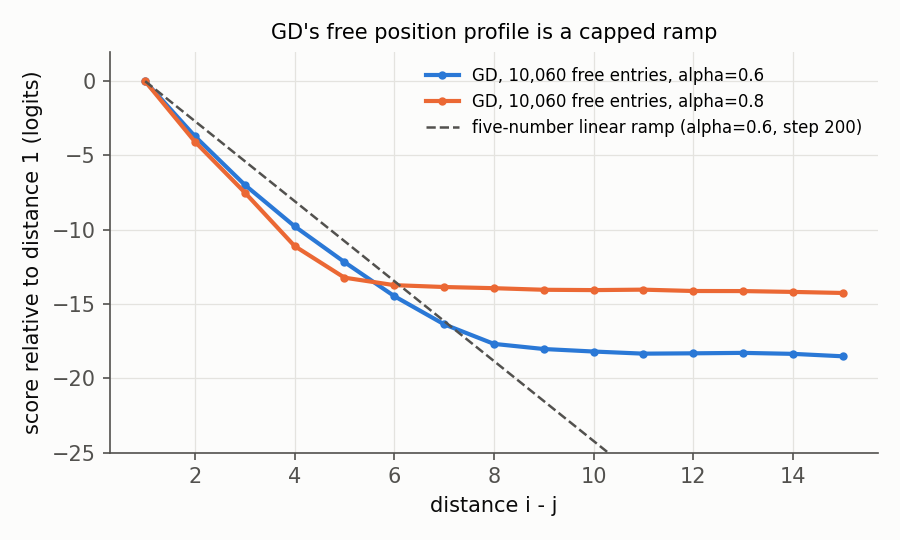

In [2]:
e0 = json.load(open(os.path.join(R, 'e0_verify.json')))
table(e0, ['alpha', 'CE folder19 class', 'CE direct', '|diff|'],
      [lambda r: f"{r['alpha']}", lambda r: f"{r['ce_f19_class']:.6f}", lambda r: f"{r['ce_direct']:.6f}", lambda r: f"{r['abs_diff']:.1e}"])
print()
e1 = json.load(open(os.path.join(R, 'e1b_functional_projection.json')))
table(list(e1.values()), ['alpha', 'folder18', 'five-trained(200)', 'naive LS', 'near-field', 'KL-matched'],
      [lambda r: f"{r['alpha']}", lambda r: f"{r['ce_folder18']:.5f}", lambda r: f"{r['ce_five_trained']:.5f}",
       lambda r: f"{r['ce_naive_ls']:.5f}", lambda r: f"{r['ce_nearfield']:.5f}", lambda r: f"{r['ce_functional']:.5f}"])
display(Image(os.path.join(FIG, 'f7_position_profile.png')))

## 2. GD learns to skip at every noise density (E4)

19 values of α, 1000 full-batch Adam steps each from zero.

  alpha    test CE    gap to ideal    L1 state mass    succ|noise    succ|signal
    0.2    1.81771          0.0696            0.954         0.884          0.912
   0.25    1.84381          0.0685            0.960         0.917          0.939
    0.3    1.85412          0.0649            0.965         0.939          0.956
   0.35    1.85349          0.0623            0.969         0.954          0.967
    0.4    1.84244          0.0604            0.974         0.965          0.974
   0.45    1.82050          0.0580            0.977         0.972          0.979
    0.5    1.79012          0.0573            0.981         0.978          0.983
   0.55    1.74876          0.0556            0.983         0.981          0.986
    0.6    1.69782          0.0544            0.987         0.985          0.988
   0.65    1.63572          0.0525            0.989         0.986          0.989
    0.7    1.56420          0.0522            0.991         0.988          0.990
   0.75    1.48170          

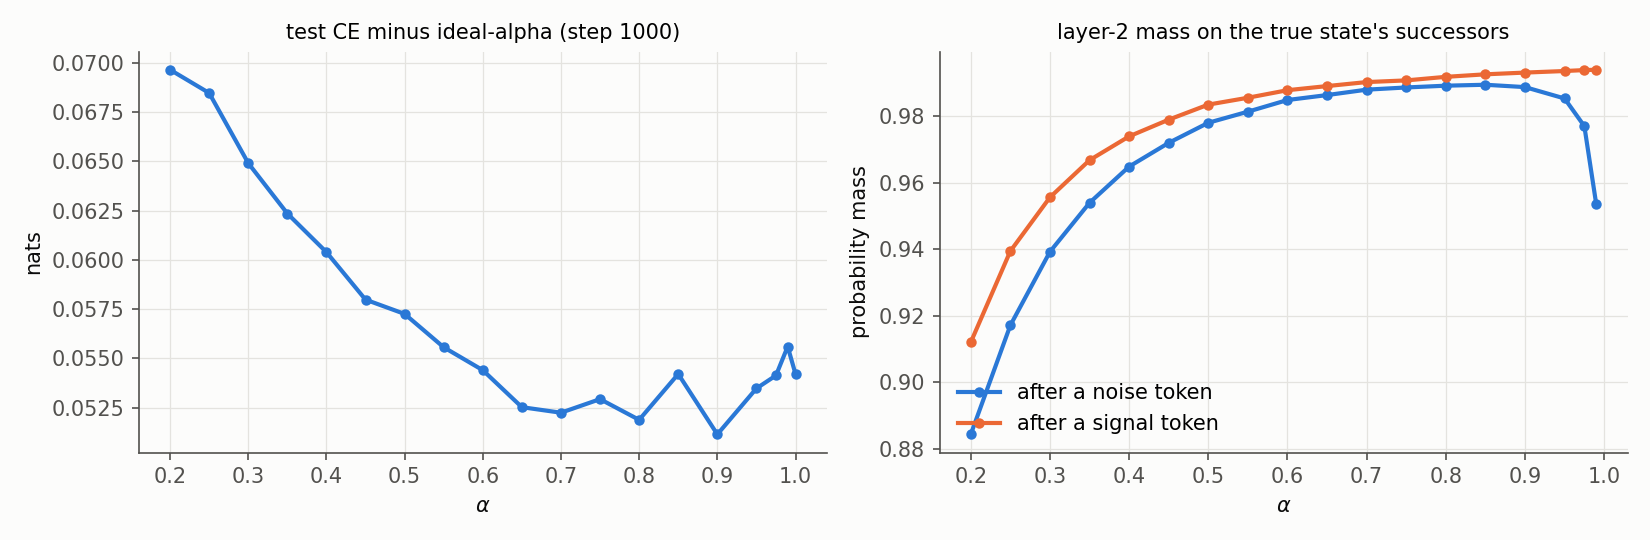

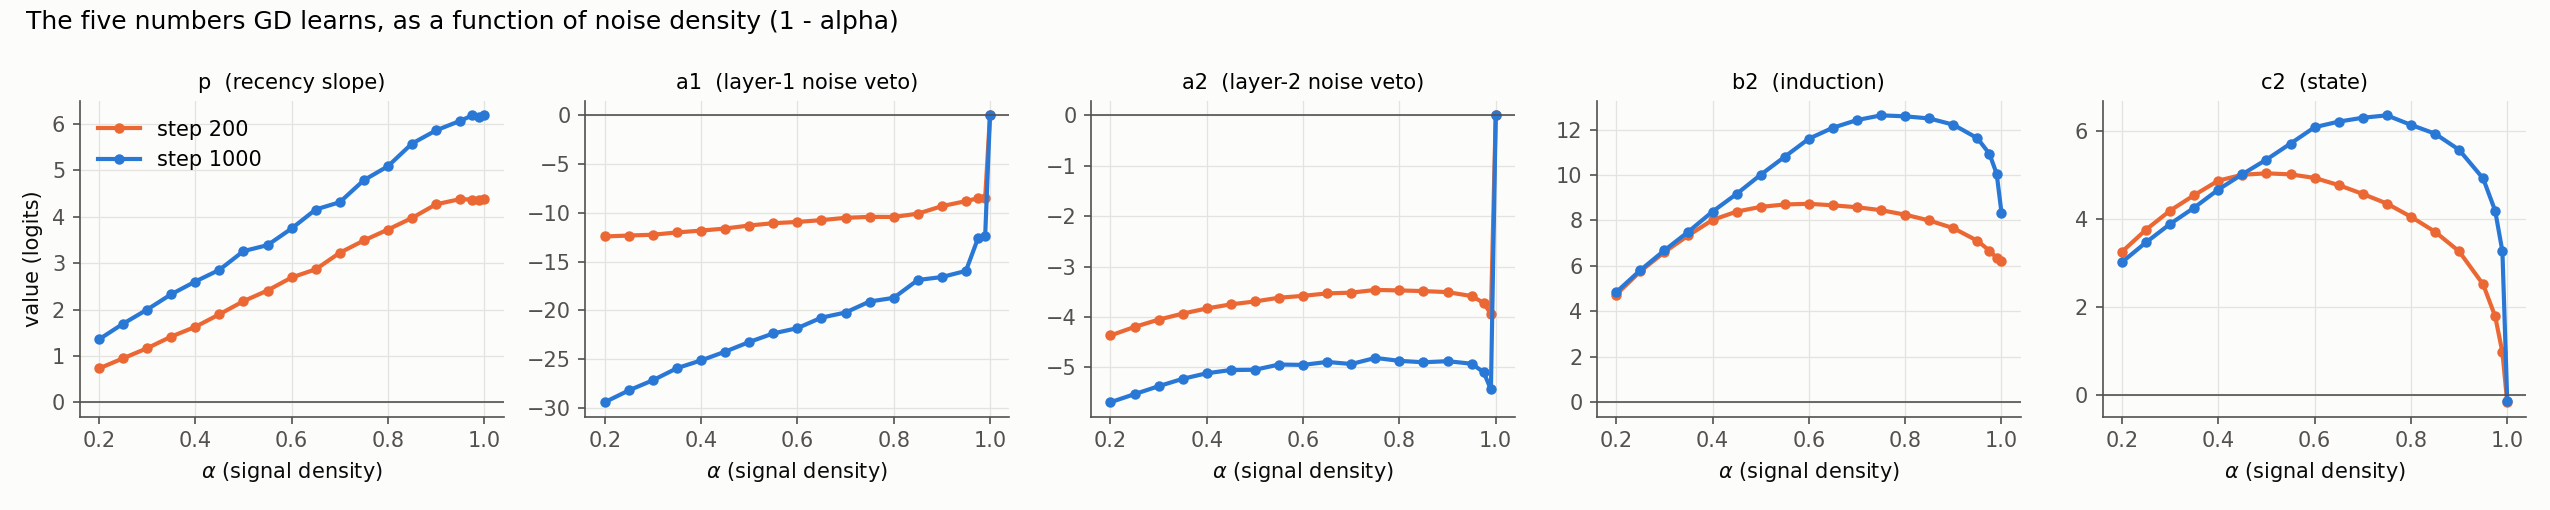

In [3]:
table(S['main'], ['alpha', 'test CE', 'gap to ideal', 'L1 state mass', 'succ|noise', 'succ|signal'],
      [lambda r: f"{r['alpha']}", lambda r: f"{r['test_ce_final']:.5f}", lambda r: f"{r['gap']:.4f}",
       lambda r: f"{r.get('final_layer1_state_mass', float('nan')):.3f}",
       lambda r: f"{r.get('final_succ_mass_postnoise', float('nan')):.3f}" if r['alpha'] < 1 else '   -',
       lambda r: f"{r.get('final_succ_mass_postsignal', float('nan')):.3f}"])
display(Image(os.path.join(FIG, 'f2_loss_gap_and_success.png')))
display(Image(os.path.join(FIG, 'f1_five_numbers_vs_alpha.png')))

## 3. How the state weight `c2` ends up positive (E2, E3, E5)

**Phase 1** (layer 1 uniform): `c2` is pulled up at every α — by keys that follow the query's
current state (a diluted state-matching signal; an *order* effect, killed by shuffling).
**Phase 2** (layer 1 learns recency): post-signal queries turn against `c2`.
**Phase 3**: the two pulls cancel. With no noise (α=1) nothing balances them and `c2` returns to ≈0.

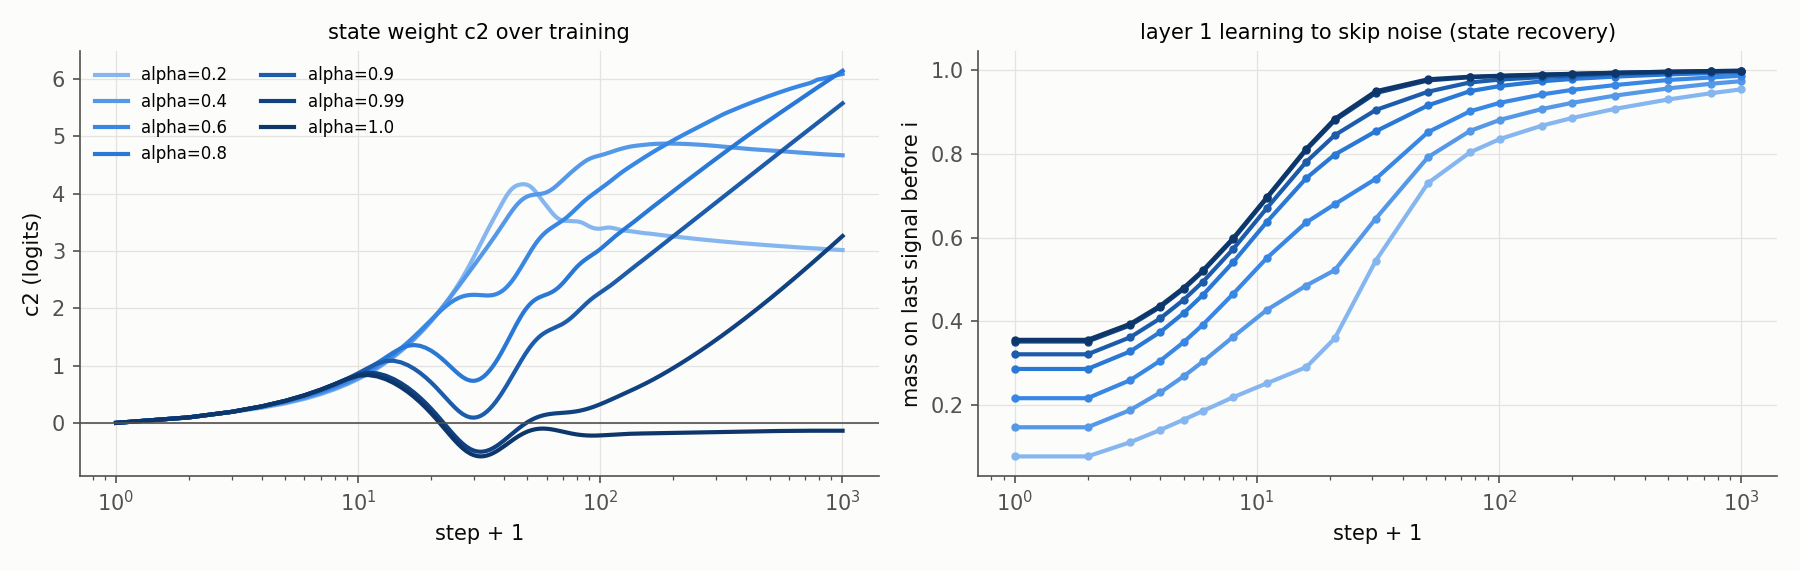

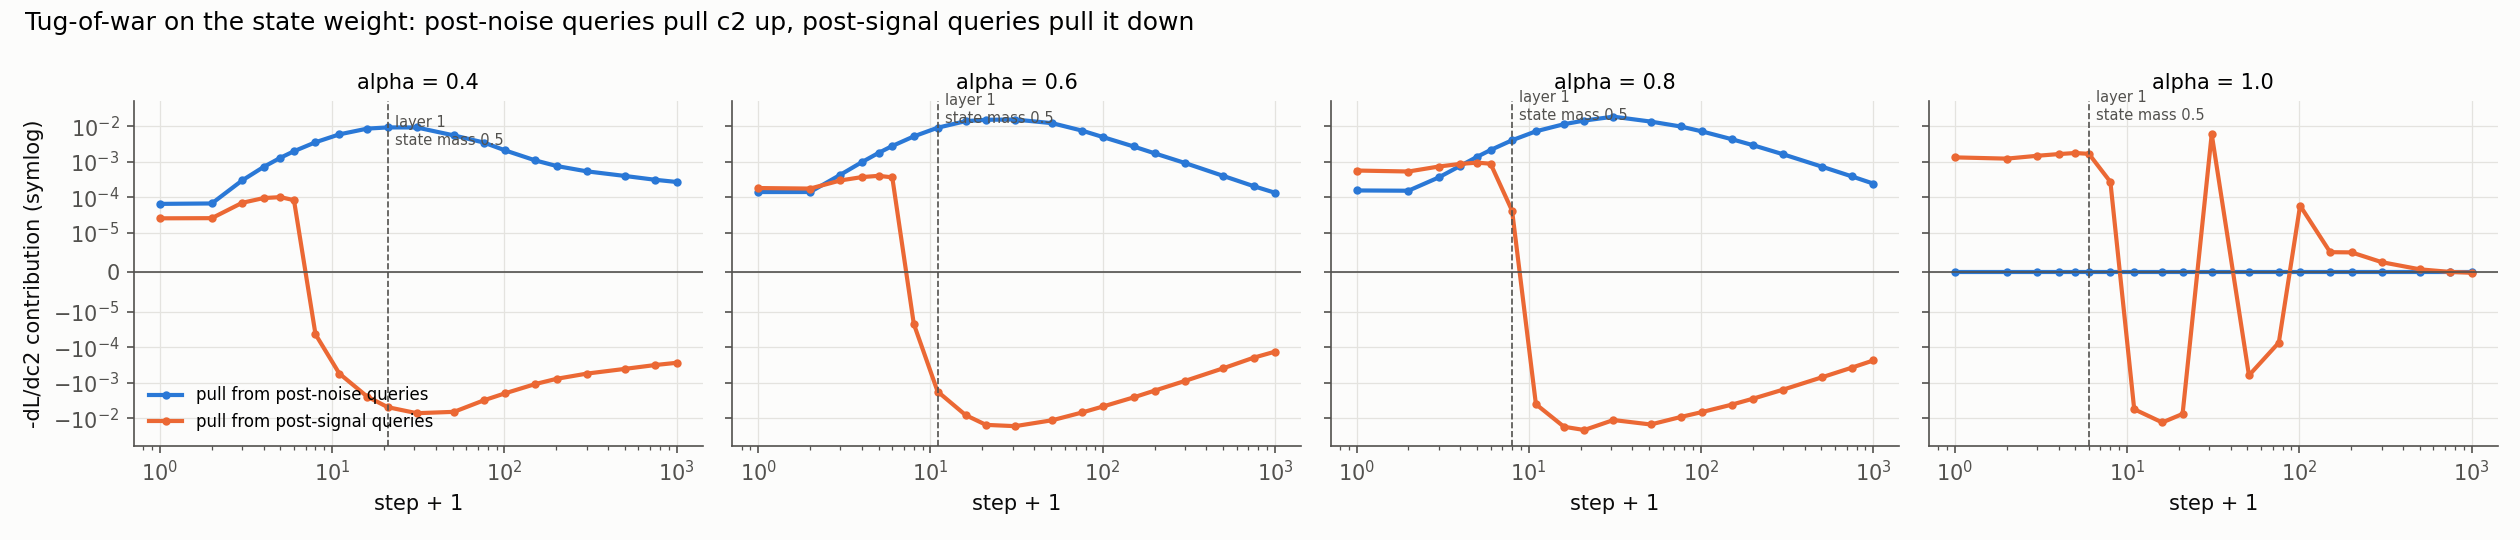


alpha=0.6:  step   c2   pull(noise)  pull(signal)  L1 state mass
            0  0.00  +1.41e-04    +1.83e-04     0.216
            3  0.28  +9.85e-04    +3.73e-04     0.306
            7  0.63  +5.21e-03    -2.19e-05     0.466
           10  0.91  +9.13e-03    -1.75e-03     0.551
           20  1.88  +1.53e-02    -1.52e-02     0.680
           30  2.23  +1.56e-02    -1.65e-02     0.740
          100  4.10  +4.94e-03    -4.57e-03     0.922
         1000  6.09  +1.35e-04    -1.32e-04     0.987

alpha=1.0:  step   c2   pull(noise)  pull(signal)  L1 state mass
            0  0.00  -0.00e+00    +1.34e-03     0.355
            3  0.29  -0.00e+00    +1.65e-03     0.437
            7  0.68  -0.00e+00    +2.73e-04     0.599
           10  0.84  -0.00e+00    -5.51e-03     0.696
           20  0.07  -0.00e+00    -7.48e-03     0.884
           30 -0.58  -0.00e+00    +6.04e-03     0.950
          100 -0.22  -0.00e+00    +5.87e-05     0.987
         1000 -0.14  -0.00e+00    -9.30e-08     0.999


In [4]:
display(Image(os.path.join(FIG, 'f3_c2_and_layer1_over_training.png')))
display(Image(os.path.join(FIG, 'f4_c2_tug_of_war.png')))
for a in ('0.6', '1.0'):
    d = json.load(open(os.path.join(R, 'main', f'anatomy_x_{a}.json')))
    print(f'\nalpha={a}:  step   c2   pull(noise)  pull(signal)  L1 state mass')
    for r in d['rows']:
        if r['step'] in (0, 3, 7, 10, 20, 30, 100, 1000):
            print(f"        {r['step']:>5} {r['theta'][4]:5.2f}  {-r['grad_noise'][4]:+.2e}    {-r['grad_signal'][4]:+.2e}     {r['layer1_state_mass']:.3f}")

-dL/dc2 at init: real sequences vs tokens shuffled within each sequence
  alpha=0.2: real +1.29e-05   shuffled +2.00e-06   | a2: real -1.06e-01 shuffled -1.05e-01
  alpha=0.4: real +9.21e-05   shuffled +4.08e-06   | a2: real -1.53e-01 shuffled -1.53e-01
  alpha=0.6: real +3.22e-04   shuffled +1.35e-05   | a2: real -1.42e-01 shuffled -1.41e-01
  alpha=0.8: real +6.98e-04   shuffled -5.54e-08   | a2: real -8.85e-02 shuffled -8.87e-02
  alpha=1.0: real +1.31e-03   shuffled -9.17e-06   | a2: real -0.00e+00 shuffled -0.00e+00


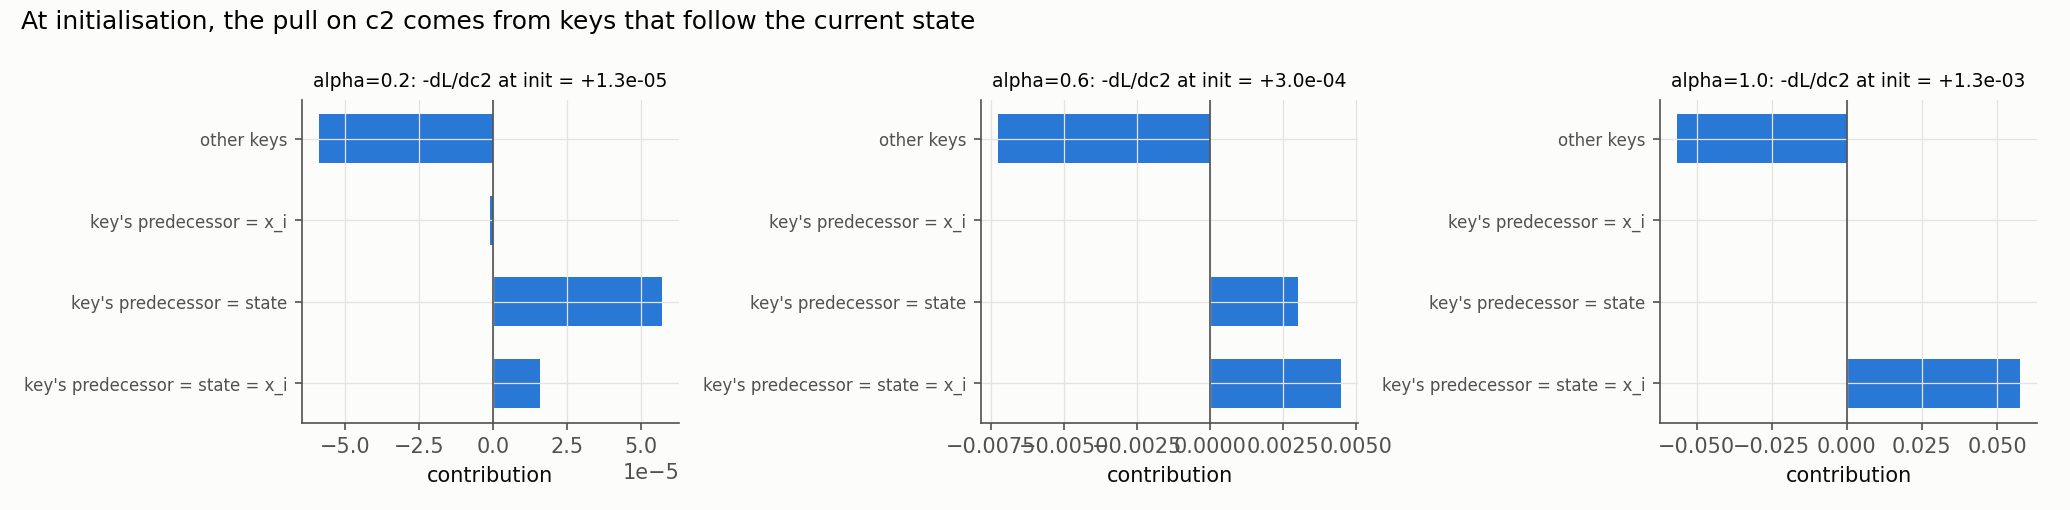

In [5]:
e3 = json.load(open(os.path.join(R, 'e3_phase1_origin.json')))
print('-dL/dc2 at init: real sequences vs tokens shuffled within each sequence')
for a, rows in e3.items():
    r = rows[0]; print(f"  alpha={a}: real {r['neg_grad_real'][4]:+.2e}   shuffled {r['neg_grad_shuffled'][4]:+.2e}"
                      f"   | a2: real {r['neg_grad_real'][2]:+.2e} shuffled {r['neg_grad_shuffled'][2]:+.2e}")
display(Image(os.path.join(FIG, 'f6_initial_pull_on_c2.png')))

In [6]:
e5 = json.load(open(os.path.join(R, 'e5_covariance_law.json')))
print('Covariance law (Prop. 3): formula vs autograd, and the hit rates behind the c2 tug-of-war')
for r in e5:
    print(f"alpha={r['alpha']} step={r['step']}: c2 formula {r['c2_formula']:+.3e} autograd {r['c2_autograd']:+.3e}")
    for t in ('postnoise', 'postsignal'):
        if f'c2_hit_favoured_{t}' in r:
            print(f"     {t:10s} keys c2 favours are right {r[f'c2_hit_favoured_{t}']:.3f} vs current {r[f'c2_hit_now_{t}']:.3f}")

Covariance law (Prop. 3): formula vs autograd, and the hit rates behind the c2 tug-of-war
alpha=0.6 step=0: c2 formula +3.169e-04 autograd +3.169e-04
     postnoise  keys c2 favours are right 0.166 vs current 0.165
     postsignal keys c2 favours are right 0.166 vs current 0.165
alpha=0.6 step=30: c2 formula -1.018e-03 autograd -1.018e-03
     postnoise  keys c2 favours are right 0.276 vs current 0.233
     postsignal keys c2 favours are right 0.206 vs current 0.250
alpha=0.6 step=1000: c2 formula -2.810e-05 autograd -2.811e-05
     postnoise  keys c2 favours are right 0.298 vs current 0.297
     postsignal keys c2 favours are right 0.263 vs current 0.296
alpha=0.2 step=1000: c2 formula +4.081e-05 autograd +4.081e-05
     postnoise  keys c2 favours are right 0.103 vs current 0.093
     postsignal keys c2 favours are right 0.077 vs current 0.095
alpha=1.0 step=10: c2 formula -5.718e-03 autograd -5.718e-03
     postsignal keys c2 favours are right 0.368 vs current 0.372
alpha=1.0 step=10

## 4. Who does what (freeze ablations)

`a1`+`p` **skip** (recover the state); `c2` **uses** it after noise; `b2` **teaches** layer 1 at
every α, while `c2` alone teaches it only when noise is dense.


freeze_c2
  alpha    test CE    L1 state mass    succ|noise    succ|signal
    0.2    1.85311            0.939         0.660          0.885
    0.4    1.92377            0.970         0.679          0.966
    0.6    1.78853            0.983         0.686          0.986
    0.8    1.44679            0.991         0.691          0.992
    1.0    0.74736            0.998         0.000          0.994

freeze_b2
  alpha    test CE    L1 state mass    succ|noise    succ|signal
    0.2    1.83507            0.949         0.837          0.657
    0.4    1.94088            0.947         0.836          0.669
    0.6    1.90283            0.826         0.779          0.686
    0.8    1.68954            0.608         0.728          0.697
    1.0    1.14763            0.366         0.000          0.698

freeze_a1
  alpha    test CE    L1 state mass    succ|noise    succ|signal
    0.2    1.85719            0.169         0.677          0.719
    0.4    1.93560            0.369         0.738        

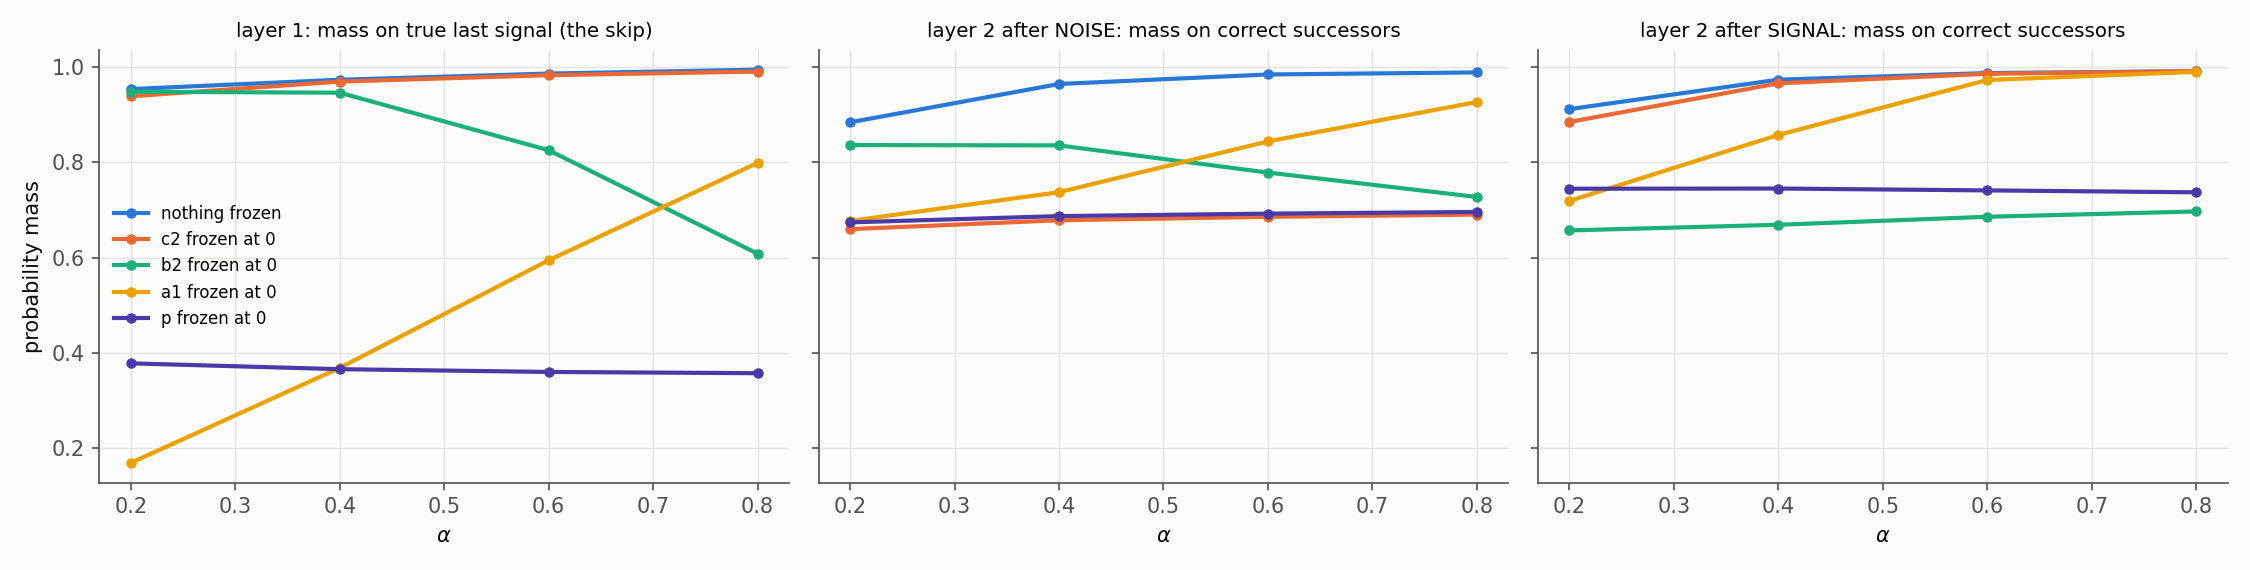

In [7]:
for tag in ('freeze_c2', 'freeze_b2', 'freeze_a1', 'freeze_p'):
    print(f'\n{tag}')
    table(S[tag], ['alpha', 'test CE', 'L1 state mass', 'succ|noise', 'succ|signal'],
          [lambda r: f"{r['alpha']}", lambda r: f"{r['test_ce_final']:.5f}",
           lambda r: f"{r.get('final_layer1_state_mass', float('nan')):.3f}",
           lambda r: f"{r.get('final_succ_mass_postnoise', float('nan')):.3f}",
           lambda r: f"{r.get('final_succ_mass_postsignal', float('nan')):.3f}"])
display(Image(os.path.join(FIG, 'f5_freeze_ablations.png')))

## 5. The skip horizon tracks the noise

`H = 1 + |a1|/p` is the farthest a signal key can be and still beat an adjacent noise key.
At any fixed step, `alpha * H` is nearly constant across alpha: the horizon is a fixed multiple of
the mean distance back to the last signal. The multiple grows slowly with training. Not derived.

In [8]:
steps = (50, 100, 200, 500, 1000)
print('alpha ' + ''.join(f'{s:>8}' for s in steps))
for f in sorted(glob.glob(os.path.join(R, 'main', 'traj_x_*.npz')), key=lambda f: float(os.path.basename(f)[7:-4])):
    a = float(os.path.basename(f)[7:-4])
    if a >= 1: continue
    th = np.load(f)['theta']
    print(f'{a:<6}' + ''.join(f'{a * (1 + abs(th[s, 1]) / th[s, 0]):8.2f}' for s in steps))

alpha       50     100     200     500    1000
0.2       3.03    3.38    3.61    4.02    4.54
0.25      2.85    3.22    3.50    3.96    4.42
0.3       2.68    3.14    3.45    3.89    4.38
0.35      2.57    2.95    3.32    3.76    4.25
0.4       2.16    2.91    3.31    3.83    4.26
0.45      2.17    2.82    3.20    3.71    4.27
0.5       2.27    2.71    3.09    3.61    4.07
0.55      2.18    2.69    3.07    3.65    4.18
0.6       2.02    2.64    3.04    3.57    4.09
0.65      1.95    2.63    3.09    3.59    3.89
0.7       1.95    2.66    2.98    3.47    3.98
0.75      1.98    2.64    2.99    3.55    3.74
0.8       2.01    2.59    3.04    3.30    3.74
0.85      2.07    2.60    3.01    3.28    3.42
0.9       2.13    2.65    2.86    3.34    3.45
0.95      2.20    2.73    2.86    3.07    3.45
0.975     2.24    2.75    2.87    2.92    2.96
0.99      2.27    2.79    2.92    2.96    2.98
